# AP 155 Lab Exercise
---
## Exercise 8: Minimization

_Instructions_: 
- **Report figure:** A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm.  
- **Report discussion:** What happens if a number other than the golden ratio is used to perform the *golden* section search algorithm?
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name_: Castaneda, Joaquin 
- _Student No._: 2024-09743
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_:_

---
## Section 1: Report

### Report figure

![Minimization](Minimization.png)

Figure 1. Plots of the functions and their identified local extrema.

### Report discussion

If a number other than the golden ratio is used, the algorithm may still work but become less efficient. The golden ratio allows the algorithm to reuse one of the previous internal points in each iteration, which requires only one new function evaluation. So, using a different ratio may lose this advantage and also require more function evaluations in order to reach the accuracy that's desired.

### Other comments

Refelction: 

I like how I got to revisit my calculus in this subject.

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Minimization

Consider the following equations:

Eq. 5.91
$$
\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4
$$

Eq. 5.145
$$
f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 - 4xe^x + 8x + 4e^x - 8
$$


1. Plot each of the functions. Get a rough estimate of the local minima and maxima
2. Implement 5.5.2.2 (golden section search), then determine the local minima and maxima of Eq. 5.91 and Eq. 5.145.
3. Report figure: A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm. 

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from math import sqrt

In [27]:
# Functions

def phi(x):
    return x**4 - 9*x**3 + 25*x**2 - 24*x + 4

def f(x):
    return (-x**5 + 4*x**4 - 4*x**3 + x**2*np.exp(x) - 2*x**2 - 4*x*np.exp(x) + 8*x + 4*np.exp(x) - 8)


# Derivatives

def dphi(x):
    return 4*x**3 - 27*x**2 + 50*x - 24

def df(x):
    return (-5*x**4 + 16*x**3 - 12*x**2 - 4*x + 8 + (x**2 - 2*x)*np.exp(x))


# Golden section search

def golden(g, x0, x1, kmax=200, tol=1.e-8):
    varphi = 0.5 * (1 + np.sqrt(5))

    for k in range(kmax):
        x2 = x0 + (x1 - x0) / (varphi + 1)
        x3 = x0 + (x1 - x0) * varphi / (varphi + 1)

        if g(x3) < g(x2):
            x0 = x2
        else:
            x1 = x3

        if abs(x1 - x0) < tol:
            return (x0 + x1) / 2

    return None


# Search brackets

intervals_phi = [(0.2, 1.0, 'min'), (1.5, 2.5, 'max'), (3.5, 4.5, 'min')]

intervals_f = [(-1.0, -0.2, 'min'), (1.5, 2.5, 'max'), (3.5, 4.5, 'min')]


# Find extrema

def find_extrema(g, intervals):
    extrema = []

    for a, b, kind in intervals:
        if kind == 'min':
            x = golden(g, a, b)
        else:
            x = golden(lambda x: -g(x), a, b)

        if x is not None:
            extrema.append((x, g(x), kind))

    return extrema


ext_phi = find_extrema(phi, intervals_phi)
ext_f = find_extrema(f, intervals_f)


# Print results

print("Extrema of phi(x):")
for x, y, kind in ext_phi:
    print(f"{kind}: x = {x:.8f}, phi(x) = {y:.8f}")

print("\nExtrema of f(x):")
for x, y, kind in ext_f:
    print(f"{kind}: x = {x:.8f}, f(x) = {y:.8f}")

Extrema of phi(x):
min: x = 0.74999999, phi(x) = -3.41796875
max: x = 1.99999996, phi(x) = 0.00000000
min: x = 4.00000001, phi(x) = -12.00000000

Extrema of f(x):
min: x = -0.67986201, f(x) = -8.46769810
max: x = 1.99999999, f(x) = 0.00000000
min: x = 4.10332484, f(x) = -46.66216526


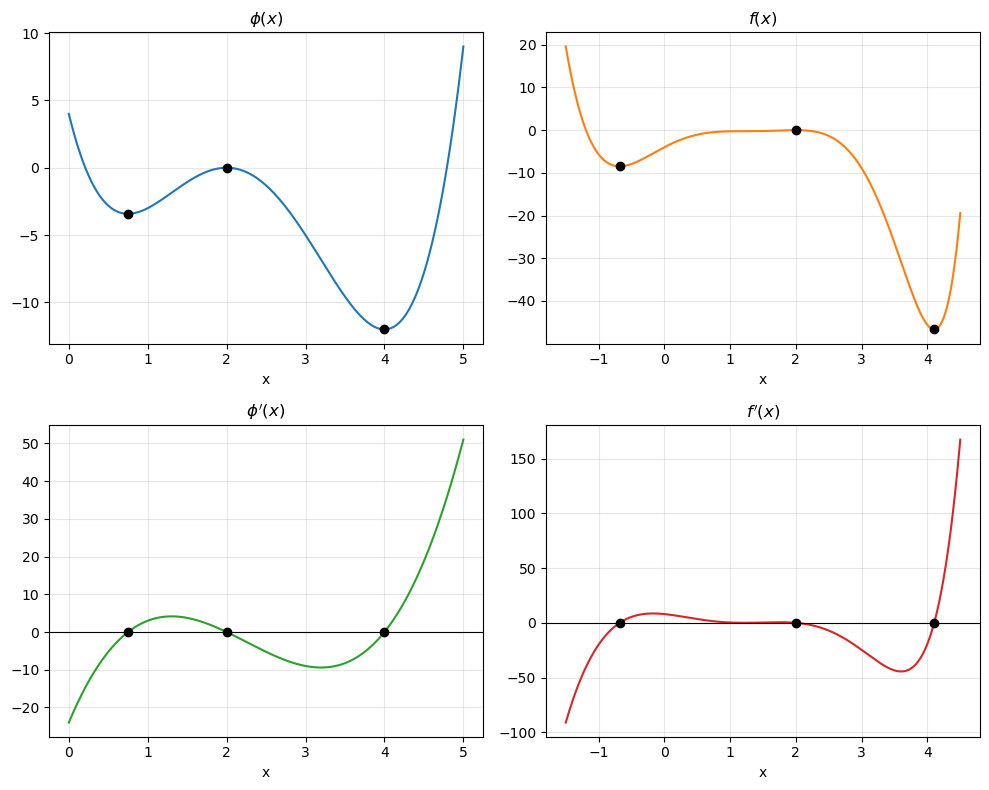

In [28]:
# Plotting

x_phi = np.linspace(0, 5, 1500)
x_f = np.linspace(-1.5, 4.5, 1500)

fig, axs = plt.subplots(2, 2, figsize=(10, 8))

# Original functions

axs[0, 0].plot(x_phi, phi(x_phi))
axs[0, 0].set_title(r'$\phi(x)$')

axs[0, 1].plot(x_f, f(x_f), color='tab:orange')
axs[0, 1].set_title(r'$f(x)$')

# Derivatives

axs[1, 0].plot(x_phi, dphi(x_phi), color='tab:green')
axs[1, 0].set_title(r"$\phi'(x)$")
axs[1, 0].axhline(0, color='black', linewidth=0.8)

axs[1, 1].plot(x_f, df(x_f), color='tab:red')
axs[1, 1].set_title(r"$f'(x)$")
axs[1, 1].axhline(0, color='black', linewidth=0.8)

# Mark extrema on functions and derivatives

for x, y, kind in ext_phi:
    axs[0, 0].plot(x, y, 'ko')
    axs[1, 0].plot(x, 0, 'ko')

for x, y, kind in ext_f:
    axs[0, 1].plot(x, y, 'ko')
    axs[1, 1].plot(x, 0, 'ko')

# Formatting

for ax in axs.flat:
    ax.grid(True, alpha=0.3)
    ax.set_xlabel('x')

fig.tight_layout()
fig.savefig('Minimization.png', dpi=300)
plt.show()

#### Problem 1 code summary

The foregoing code uses the golden section search algorithm to find local minima and maxima within predefined intervals. Maxima are found by minimizing the negated function. The script also plots the functions, their derivatives, and the identified extrema.

**End of Notebook.**